# 8.0 Regresión Lineal por Mínimos Cuadrados en JobPath (`IDEA-RL-01`, `RL-02`, `RL-04`, `RL-05`)

**Alineación con la presentación:** `regresion_lineal_minimos_cuadrados.html` (Prof. Juan Carlos González Sánchez · UNIMINUTO Ibagué)  
**Proyecto:** JobPath (`MineriaProtect`) · Extensión de Modelado Numérico CRISP-DM  
**Alcance:** Ejecuta y audita las 4 ideas núcleo de Regresión Lineal por Mínimos Cuadrados Ordinarios (MCO) sobre las 4 capas de `data/` (`01_raw`, `02_interim`, `03_processed`, `04_transformed`) mediante ecuaciones normales en forma cerrada verificadas contra `numpy.polyfit(x, y, 1)` (`< 1e-10`) y GeoGebra.

> **Salvaguardas de Dominio (`MR-07`, `MR-08`, `MR-09`):** Todas las pendientes miden **asociaciones descriptivas**, nunca causalidad. Los conteos ESCO expresan *cuántas competencias exige una ocupación*, nunca *cuántas posee o sabe la persona*. Todos los archivos en `data/` permanecen estrictamente en modo solo lectura.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
for cand in (ROOT, *ROOT.parents):
    if (cand / "data").is_dir() and (cand / "scripts").is_dir():
        ROOT = cand
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.MetodosNumericos.config import default_config
from scripts.ScriptsCsv.MetodosNumericos.ols import regresion_lineal

cfg = default_config(ROOT)
tdir, fdir = cfg.tables_dir, cfg.figures_dir

# Cambiar a True para recalcular todo el pipeline sobre los 22 GB de datos desde cero
RECOMPUTE_FULL_PIPELINE = False
if RECOMPUTE_FULL_PIPELINE or not (tdir / "ols_summary_all_ideas.csv").exists():
    from scripts.ScriptsCsv.MetodosNumericos.pipeline import run_all_8_ideas
    run_all_8_ideas(cfg)

print(f"Carpeta de tablas:  {tdir}")
print(f"Carpeta de figuras: {fdir}")

Carpeta de tablas:  C:\Users\ASUS\Documents\MINERIA2\MineriaProtect\reports\metodos_numericos_jobpath\tables
Carpeta de figuras: C:\Users\ASUS\Documents\MINERIA2\MineriaProtect\reports\metodos_numericos_jobpath\figures


## 1. Verificación del Motor con los Ejemplos de la Presentación (Diapositivas 6–13)

Antes de auditar las tablas de JobPath, verificamos `regresion_lineal(x, y)` desde primeros principios frente al ejemplo guiado de **Carga de Servidor** (`a1 ≈ 28.5714`, `a0 ≈ 91.6667`, `R² ≈ 0.9898`, `Sy/x ≈ 6.0749`) y el ejercicio de práctica **LOC** (`a1 = 2.05`, `a0 = 0.70`).

In [2]:
srv = regresion_lineal([1, 2, 3, 4, 5, 6], [120, 145, 185, 200, 240, 260], name="Ejemplo Carga Servidor")
loc = regresion_lineal([2, 4, 6, 8, 10], [5, 9, 12, 18, 21], name="Práctica LOC")
pd.DataFrame([srv.to_dict(), loc.to_dict()])[["name", "n", "a0", "a1", "r", "r2", "s_yx", "centroid_err", "polyfit_max_abs_diff"]]

,name,n,a0,a1,r,r2,s_yx,centroid_err,polyfit_max_abs_diff
0,Ejemplo Carga Servidor,6,91.666667,28.571429,0.994873,0.989772,6.074929,0.0,9.947598e-14
1,Práctica LOC,5,0.700000,2.050000,0.994396,0.988824,0.795822,0.0,1.387779e-14


## 2. `IDEA-RL-01` — Progresión por Paso de Carrera por MCO (`job_order` $k = 1 \dots 10$)

**Propósito:** Cuantificar cómo escalan la media de competencias esenciales exigidas por la ocupación, la tasa de reincidencia en el oficio, la duración promedio del empleo y la intensidad verde ocupacional (`greenShare`, integrada desde `data/02_interim/ESCO/greenShareOcc_en_limpio.csv`) a lo largo de los pasos $k = 1 \dots 10$, incluyendo verificación de sensibilidad controlada por cohorte (personas con $\ge 10$ empleos), tabla paso a paso de sumatorias/residuos y auditoría de extrapolación ($k = 11, 12, 15$).

In [3]:
rl01_ols = pd.read_csv(tdir / "rl01_ols_summary.csv")
display(rl01_ols[["idea_id", "y_var", "n", "a0", "a1", "r", "r2", "s_yx", "quality_verdict", "polyfit_max_abs_diff"]])

print("\nTabla paso a paso de sumatorias y residuos para mean_skills ~ job_order (Diapositivas 7 y 11):")
display(pd.read_csv(tdir / "rl01_summation_and_residuals_skills.csv"))

print("\nAuditoría de extrapolación controlada (k = 11, 12, 15 frente a valores observados):")
display(pd.read_csv(tdir / "rl01_extrapolation_audit.csv"))

,idea_id,y_var,n,a0,a1,r,r2,s_yx,quality_verdict,polyfit_max_abs_diff
0,IDEA-RL-01,mean_skills,10,22.516043,0.224971,0.997746,0.995498,0.048586,Strong Linear Fit (R2 >= 0.70),3.552714e-15
1,IDEA-RL-01 (cohort >=10),mean_skills,10,22.912194,0.202600,0.976179,0.952926,0.144605,Strong Linear Fit (R2 >= 0.70),3.552714e-15
2,IDEA-RL-01,reincide_rate,10,0.220620,0.021255,0.981068,0.962494,0.013474,Strong Linear Fit (R2 >= 0.70),5.551115e-17
3,IDEA-RL-01 (cohort >=10),reincide_rate,10,0.380646,0.007234,0.668954,0.447499,0.025813,Moderate Linear Fit (0.30 <= R2 < 0.70),4.336809e-18
4,IDEA-RL-01,mean_dur_q,10,15.814976,-0.809393,-0.951314,0.904998,0.842141,Strong Linear Fit (R2 >= 0.70),3.330669e-16
5,IDEA-RL-01 (cohort >=10),mean_dur_q,10,13.710601,-0.581499,-0.940110,0.883808,0.677081,Strong Linear Fit (R2 >= 0.70),3.552714e-15
6,IDEA-RL-01,mean_green,10,0.023625,-0.000219,-0.887543,0.787733,0.000365,Strong Linear Fit (R2 >= 0.70),3.469447e-18
7,IDEA-RL-01 (cohort >=10),mean_green,10,0.019152,0.000183,0.854991,0.731010,0.000357,Strong Linear Fit (R2 >= 0.70),3.469447e-18



Tabla paso a paso de sumatorias y residuos para mean_skills ~ job_order (Diapositivas 7 y 11):


,i,x_i,y_i,x_i_sq,x_i_y_i,y_hat_i,e_i,e_i_sq,y_minus_ybar_sq
0,1,1.0,22.693871,1.0,22.693871,22.741015,-0.047144,2.222546e-03,1.122570
1,2,2.0,22.977992,4.0,45.955984,22.965986,0.012006,1.441558e-04,0.601234
2,3,3.0,23.207698,9.0,69.623094,23.190957,0.016741,2.802656e-04,0.297774
3,4,4.0,23.435402,16.0,93.741609,23.415928,0.019474,3.792466e-04,0.101113
4,5,5.0,23.679668,25.0,118.398342,23.640899,0.038769,1.503040e-03,0.005434
5,6,6.0,23.884766,36.0,143.308598,23.865870,0.018896,3.570578e-04,0.017261
6,7,7.0,24.084861,49.0,168.594024,24.090842,-0.005981,3.577236e-05,0.109876
7,8,8.0,24.210442,64.0,193.683534,24.315813,-0.105371,1.110305e-02,0.208901
8,9,9.0,24.594249,81.0,221.348244,24.540784,0.053465,2.858550e-03,0.707053
9,10,10.0,24.764899,100.0,247.648987,24.765755,-0.000856,7.334775e-07,1.023160



Auditoría de extrapolación controlada (k = 11, 12, 15 frente a valores observados):


,y_var,job_order_k,is_extrapolation,y_pred_ols,y_observed,abs_error,observed_n_rows
0,mean_skills,11,True,24.990726,24.864747,0.125979,16044
1,mean_skills,12,True,25.215697,25.192637,0.023060,10159
2,mean_skills,15,True,25.890611,25.828202,0.062409,2241
3,reincide_rate,11,True,0.454424,0.439167,0.015257,16044
4,reincide_rate,12,True,0.475679,0.450930,0.024749,10159
5,reincide_rate,15,True,0.539444,0.485498,0.053946,2241
6,mean_dur_q,11,True,6.911649,8.393293,1.481644,16044
7,mean_dur_q,12,True,6.102256,8.105227,2.002971,10159
8,mean_dur_q,15,True,3.674076,7.625614,3.951537,2241
9,mean_green,11,True,0.021219,0.019936,0.001283,16044


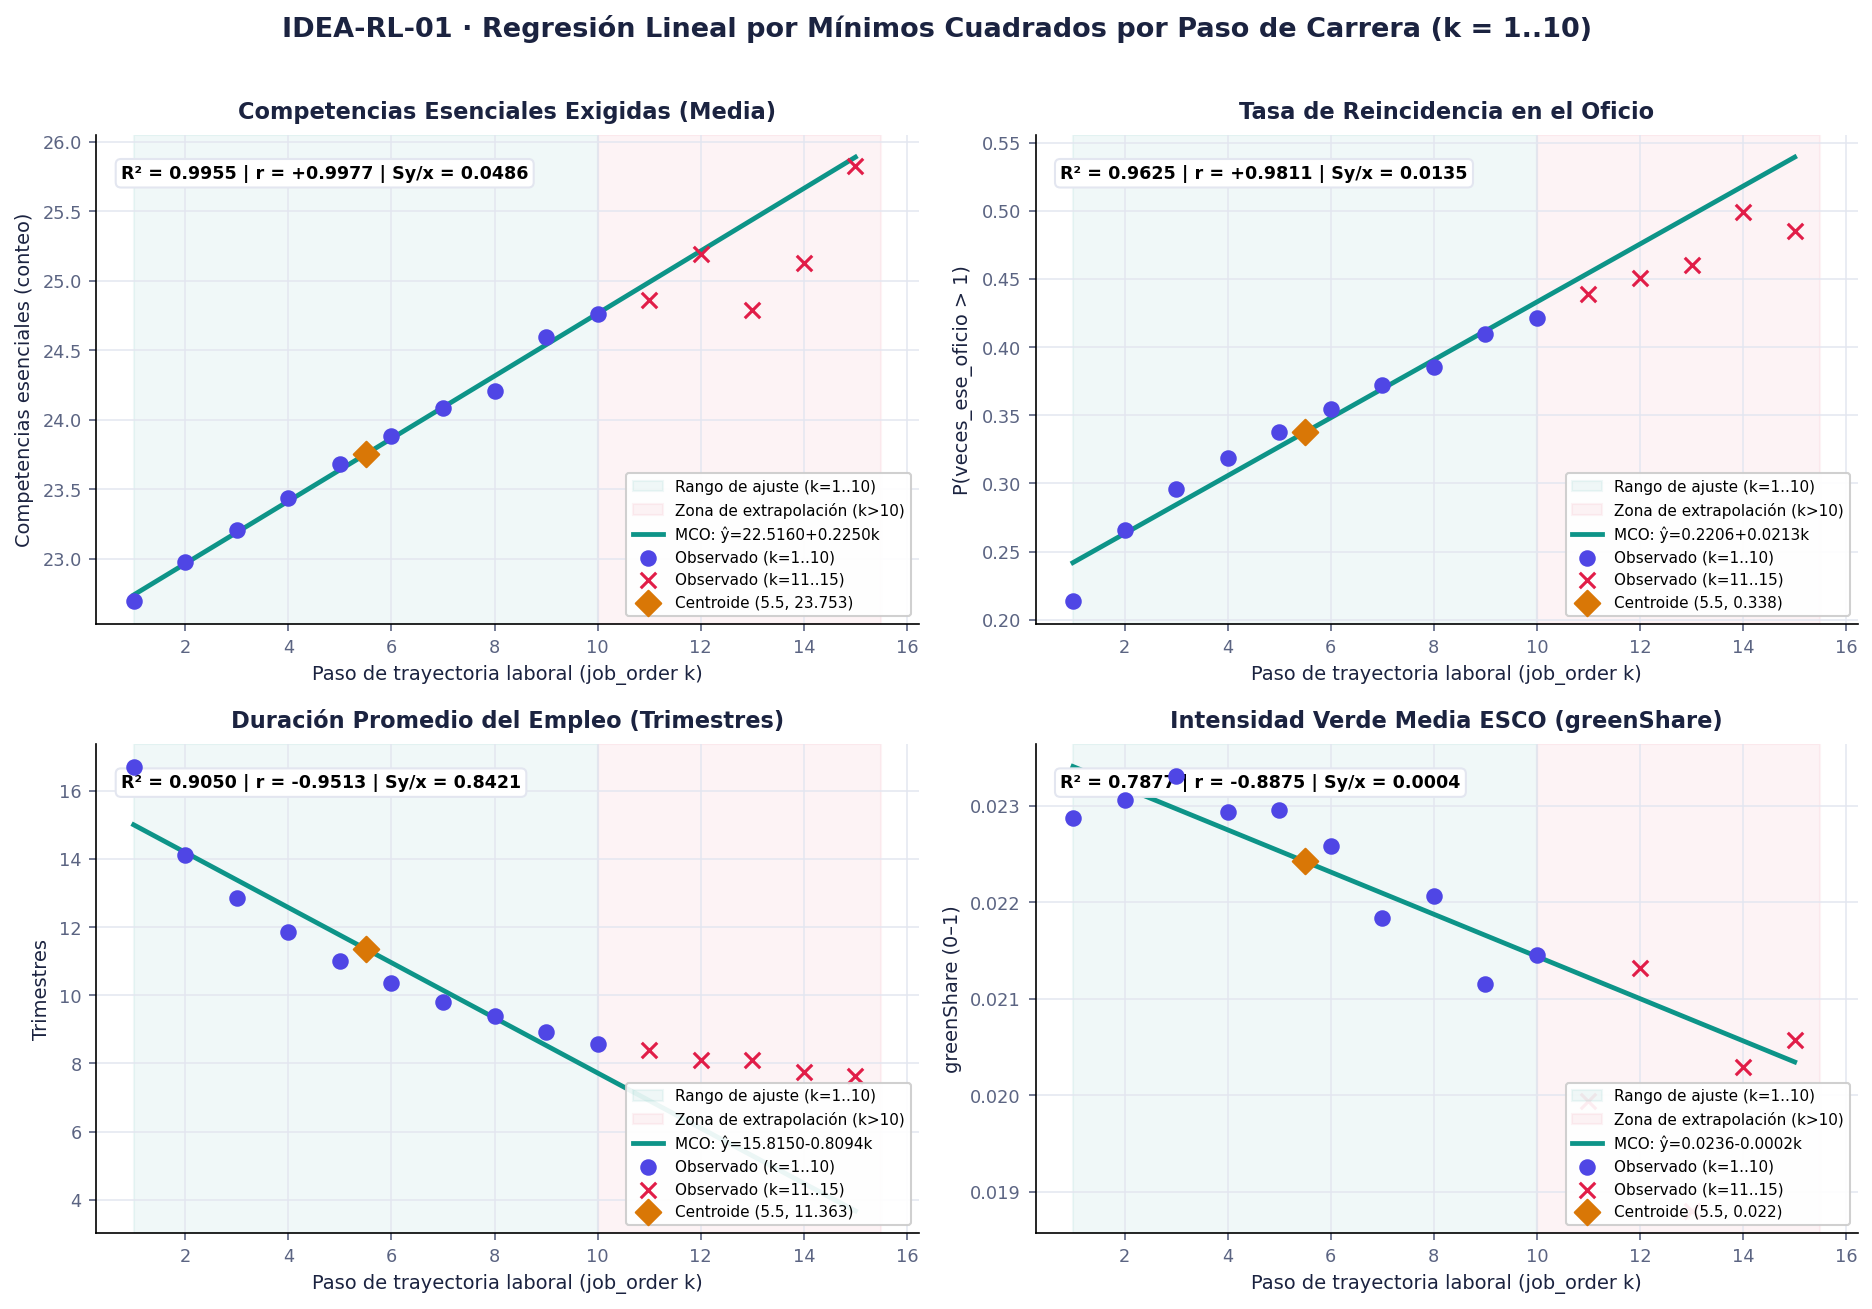

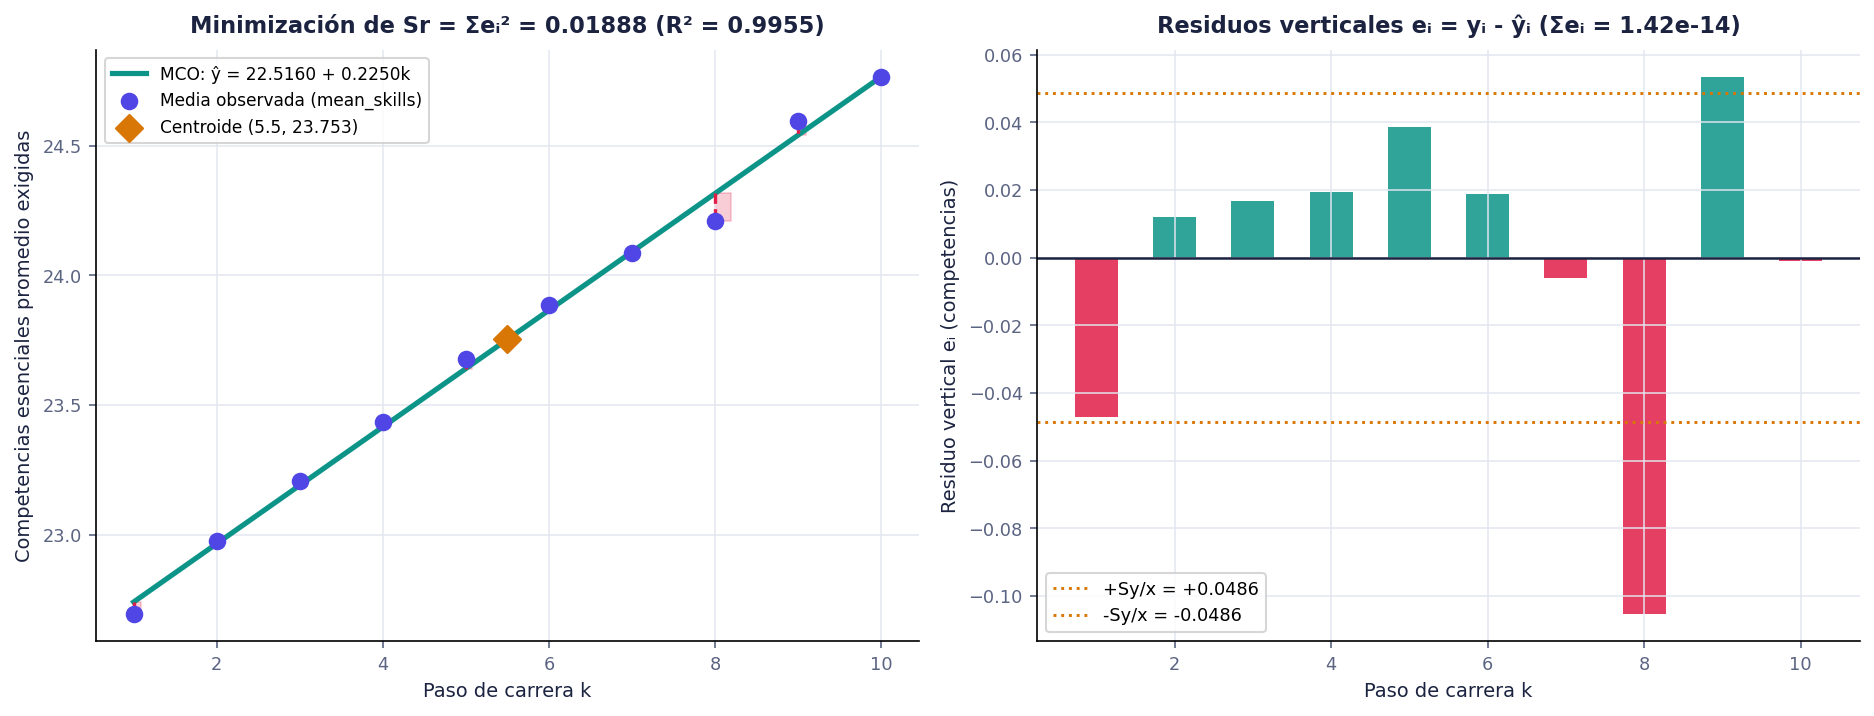

In [4]:
display(Image(filename=str(fdir / "nm01_rl01_career_steps_panel.png")))
display(Image(filename=str(fdir / "nm02_rl01_residual_squares_and_extrapolation.png")))

## 3. `IDEA-RL-02` — Ontología ESCO y Arquitectura de Transferibilidad de Competencias ($n = 3,039$ Ocupaciones)

**Propósito:** Modelar leyes estructurales de escalamiento en `01_raw/{ESCO,SKILLS}` y `02_interim/{ESCO,SKILLS}`—contrastando acoplamientos fuertes/moderados (`n_essential ~ n_ess_comp`, `n_cross_sector ~ n_total_rel`) frente a **modelos honestamente rechazados por bajo $R^2$** (`n_optional ~ n_essential`, `greenShare ~ n_essential`, Diapositiva 13), más la estratificación por los 10 grandes grupos ISCO-08.

In [5]:
rl02_ols = pd.read_csv(tdir / "rl02_esco_catalog_ols.csv")
display(rl02_ols[["idea_id", "x_var", "y_var", "n", "a0", "a1", "r", "r2", "s_yx", "quality_verdict", "polyfit_max_abs_diff"]])

print("\nPendientes de transferibilidad intersectorial por gran grupo ISCO-08:")
display(pd.read_csv(tdir / "rl02_isco_major_group_slopes.csv"))

,idea_id,x_var,y_var,n,a0,a1,r,r2,s_yx,quality_verdict,polyfit_max_abs_diff
0,IDEA-RL-02,n_ess_comp,n_essential,3039,3.346463,1.122668,0.929665,0.864277,4.418374,Strong Linear Fit (R2 >= 0.70),4.440892e-15
1,IDEA-RL-02,n_competence,n_total_rel,3039,4.835945,1.215555,0.855498,0.731877,10.470211,Strong Linear Fit (R2 >= 0.70),1.776357e-15
2,IDEA-RL-02,n_total_rel,n_cross_sector,3039,-0.798308,0.578584,0.753019,0.567037,10.222900,Moderate Linear Fit (0.30 <= R2 < 0.70),4.662937e-15
3,IDEA-RL-02,n_sector_spec,n_total_rel,3039,24.553393,0.992460,0.637854,0.406858,15.572823,Moderate Linear Fit (0.30 <= R2 < 0.70),1.776357e-14
4,IDEA-RL-02,n_essential,n_optional,3039,15.959246,0.147202,0.118307,0.013997,14.817612,Weak / Rejected Linear Model (R2 < 0.30),1.953993e-14
5,IDEA-RL-02,n_essential,greenShare,3039,0.043507,-0.000052,-0.006689,0.000045,0.093333,Weak / Rejected Linear Model (R2 < 0.30),9.020562e-17
6,IDEA-RL-02,n_knowledge,greenShare,3039,0.035976,0.000563,0.065704,0.004317,0.093133,Weak / Rejected Linear Model (R2 < 0.30),4.163336e-17
7,IDEA-RL-02 (ISCO-10 centroids),mean_total_rel,mean_cross_sector,10,3.448113,0.432990,0.529160,0.280010,5.431050,Weak / Rejected Linear Model (R2 < 0.30),1.065814e-14



Pendientes de transferibilidad intersectorial por gran grupo ISCO-08:


,isco_major,isco_major_label,n_occupations,mean_essential,mean_total_rel,mean_cross_sector,mean_greenshare,a0,a1_cross_sector_slope,r2,s_yx,quality_verdict
0,0,Armed forces occupations,21,16.190476,35.666667,25.619048,0.003685,0.116196,0.715033,0.922008,4.274394,Strong Linear Fit (R2 >= 0.70)
1,1,Managers,350,25.714286,40.822857,25.217143,0.039471,-5.002873,0.740272,0.754064,7.670015,Strong Linear Fit (R2 >= 0.70)
2,2,Professionals,868,27.437788,53.176267,30.895161,0.046097,1.625446,0.550428,0.501072,13.851646,Moderate Linear Fit (0.30 <= R2 < 0.70)
3,3,Technicians and associate professionals,646,21.221362,38.473684,21.561920,0.048030,3.423901,0.471440,0.442059,8.848327,Moderate Linear Fit (0.30 <= R2 < 0.70)
4,4,Clerical support workers,89,16.752809,29.280899,16.213483,0.022708,-3.735647,0.681302,0.521912,6.259908,Moderate Linear Fit (0.30 <= R2 < 0.70)
5,5,Service and sales workers,204,21.784314,35.284314,15.882353,0.016974,1.188956,0.416429,0.268735,7.761175,Weak / Rejected Linear Model (R2 < 0.30)
6,6,"Skilled agricultural, forestry and fishery wor...",44,28.022727,46.590909,12.295455,0.137010,-3.220088,0.333017,0.605036,4.190298,Moderate Linear Fit (0.30 <= R2 < 0.70)
7,7,Craft and related trades workers,394,17.469543,37.723350,21.200508,0.035130,-2.926313,0.639573,0.616449,7.366794,Moderate Linear Fit (0.30 <= R2 < 0.70)
8,8,Plant and machine operators and assemblers,347,15.850144,31.438040,16.740634,0.036594,-4.759129,0.683877,0.613380,6.534814,Moderate Linear Fit (0.30 <= R2 < 0.70)
9,9,Elementary occupations,76,15.578947,31.276316,13.276316,0.075213,3.482671,0.313133,0.361823,5.906424,Moderate Linear Fit (0.30 <= R2 < 0.70)


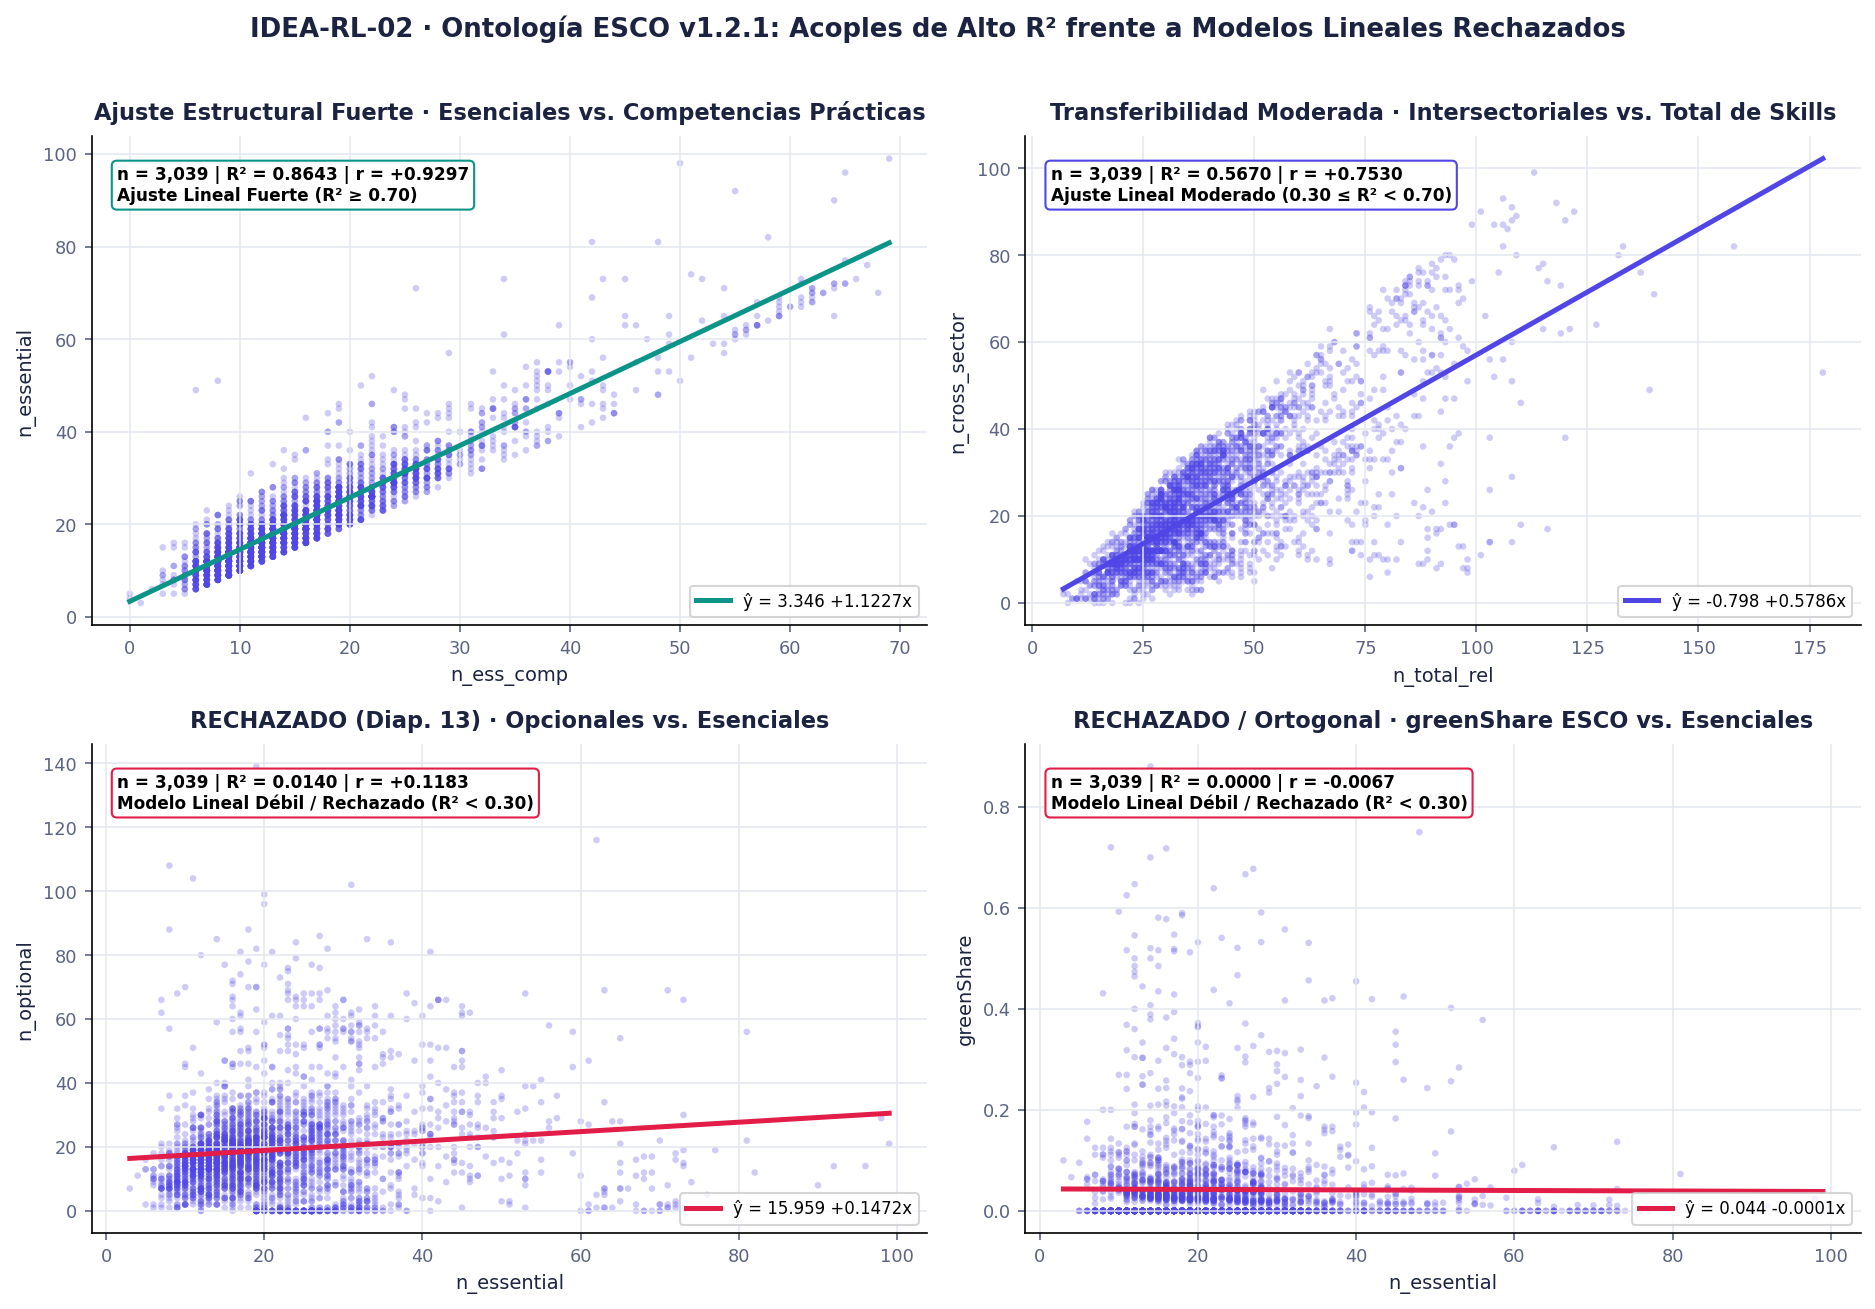

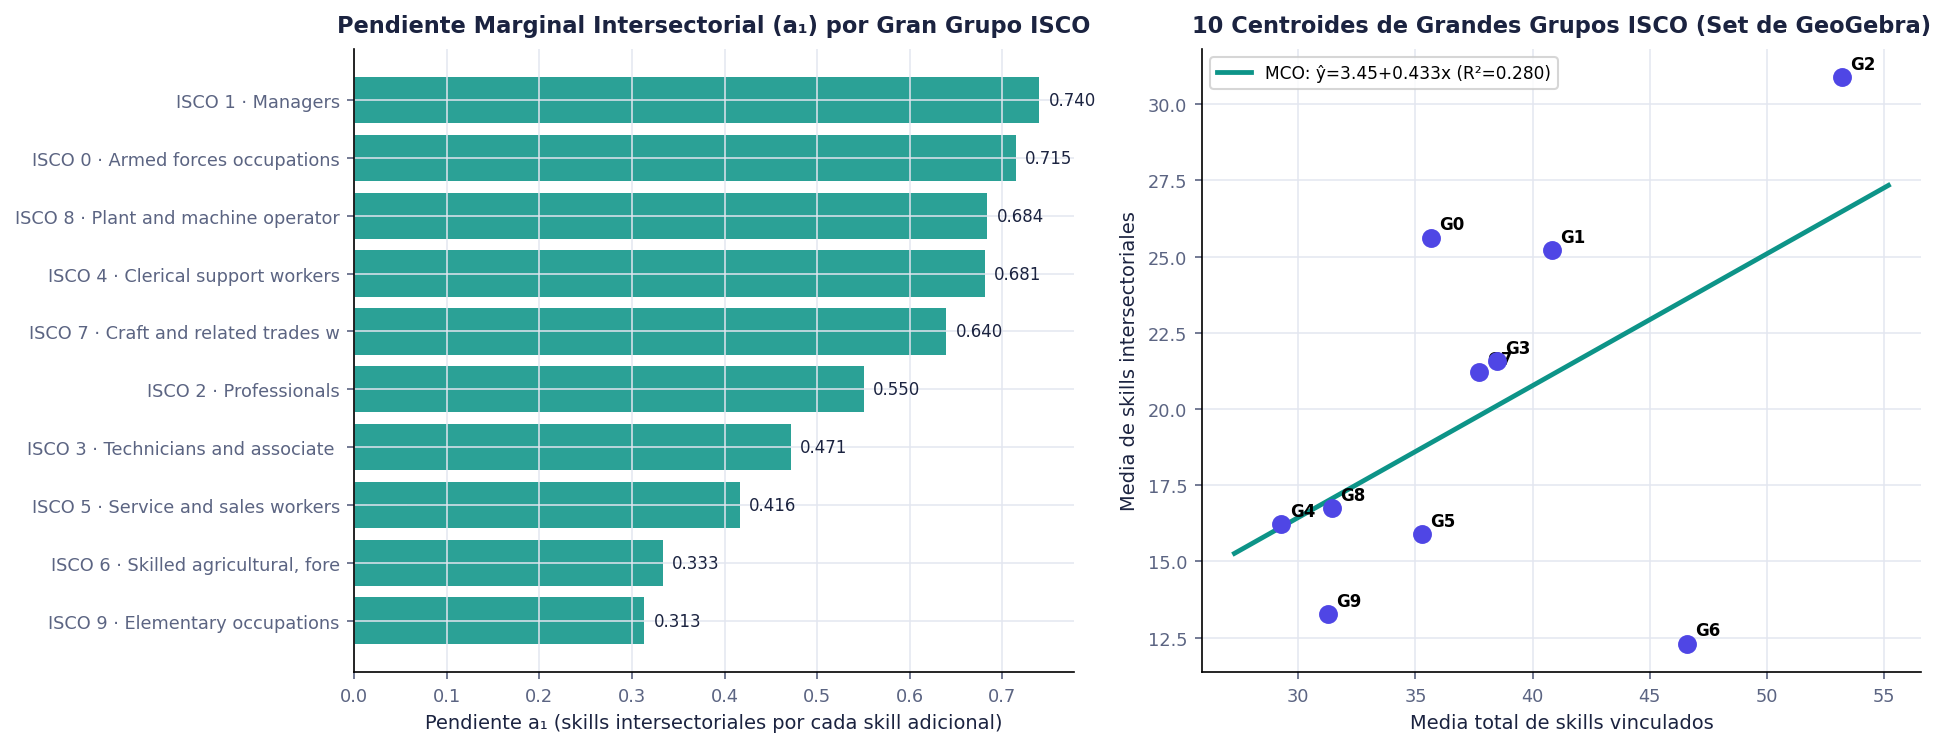

In [6]:
display(Image(filename=str(fdir / "nm03_rl02_esco_high_vs_low_r2.png")))
display(Image(filename=str(fdir / "nm04_rl02_isco_major_group_slopes.png")))

## 4. `IDEA-RL-04` — Deriva Macro Anual y Fallo de Extrapolación por Censura Derecha

**Propósito:** Medir tendencias macro de 20 años (`2000–2019`), auditar la paridad de particiones crudas `train`/`test`/`val` (`01_raw`) y demostrar empíricamente la **advertencia de extrapolación de la Diapositiva 12**: incluir la cola dispersa censurada `2020–2023` (`n = 59, 3, 3, 1`) desploma el $R^2$ de `mean_skills` de `0.7475` a `0.0826`, y extrapolar `mean_dur_q` más allá de 2026 produce duraciones físicamente imposibles (negativas).

In [7]:
rl04_reg = pd.read_csv(tdir / "rl04_ols_regime_comparison.csv")
display(rl04_reg.loc[rl04_reg["regime"] != "Centered valid (t-2000, n=20)", ["y_var", "regime", "n", "a1", "r", "r2", "s_yx", "quality_verdict"]])

print("\nAuditoría de fallo de extrapolación (2020-2027 proyectado desde MCO 2000-2019):")
display(pd.read_csv(tdir / "rl04_extrapolation_failure_audit.csv"))

print("\nAuditoría de paridad de particiones crudas 01_raw (JobHop_v2_train / test / val):")
display(pd.read_csv(tdir / "rl04_raw_partition_parity.csv"))

,y_var,regime,n,a1,r,r2,s_yx,quality_verdict
0,mean_skills,"Valid support (2000-2019, n=20)",20,0.096731,0.864593,0.747521,0.341699,Strong Linear Fit (R2 >= 0.70)
1,mean_skills,"Censored tail included (2000-2023, n=24)",24,-0.101080,-0.287478,0.082644,2.434808,Weak / Rejected Linear Model (R2 < 0.30)
3,mean_dur_q,"Valid support (2000-2019, n=20)",20,-0.709603,-0.963723,0.928761,1.194527,Strong Linear Fit (R2 >= 0.70)
4,mean_dur_q,"Censored tail included (2000-2023, n=24)",24,-0.658723,-0.956172,0.914266,1.458418,Strong Linear Fit (R2 >= 0.70)
6,mean_green,"Valid support (2000-2019, n=20)",20,-0.000124,-0.811930,0.659230,0.000541,Moderate Linear Fit (0.30 <= R2 < 0.70)
7,mean_green,"Censored tail included (2000-2023, n=24)",24,-0.000417,-0.413954,0.171358,0.006623,Weak / Rejected Linear Model (R2 < 0.30)
9,reincide_rate,"Valid support (2000-2019, n=20)",20,0.001177,0.656730,0.431295,0.008218,Moderate Linear Fit (0.30 <= R2 < 0.70)
10,reincide_rate,"Censored tail included (2000-2023, n=24)",24,-0.005394,-0.432488,0.187046,0.081302,Weak / Rejected Linear Model (R2 < 0.30)
12,n_starts,"Valid support (2000-2019, n=20)",20,2717.896992,0.411287,0.169157,36611.860848,Weak / Rejected Linear Model (R2 < 0.30)
13,n_starts,"Censored tail included (2000-2023, n=24)",24,-1053.930000,-0.163077,0.026594,46100.243513,Weak / Rejected Linear Model (R2 < 0.30)



Auditoría de fallo de extrapolación (2020-2027 proyectado desde MCO 2000-2019):


,y_var,year,is_extrapolation,y_pred_from_2000_2019,y_observed,observed_n_starts,physically_invalid
0,mean_skills,2020,True,24.301841,23.966102,59,False
1,mean_skills,2021,True,24.398573,23.333333,3,False
2,mean_skills,2022,True,24.495304,15.666667,3,False
3,mean_skills,2023,True,24.592035,14.000000,1,False
4,mean_skills,2026,True,24.882230,NaN,0,False
5,mean_skills,2027,True,24.978961,NaN,0,False
6,mean_dur_q,2020,True,4.404223,6.457627,59,False
7,mean_dur_q,2021,True,3.694620,8.333333,3,False
8,mean_dur_q,2022,True,2.985016,3.000000,3,False
9,mean_dur_q,2023,True,2.275413,2.000000,1,False



Auditoría de paridad de particiones crudas 01_raw (JobHop_v2_train / test / val):


,raw_file,total_rows_raw,null_start_date_rows,rows_2000_2019,share_slope_pct_per_yr,share_r2,polyfit_max_abs_diff
0,raw_train,1594827,58312,1337511,0.185451,0.174969,3.353762e-12
1,raw_test,198877,7085,166437,0.180815,0.167817,2.899014e-12
2,raw_val,199587,7329,167401,0.184751,0.174730,3.240075e-12


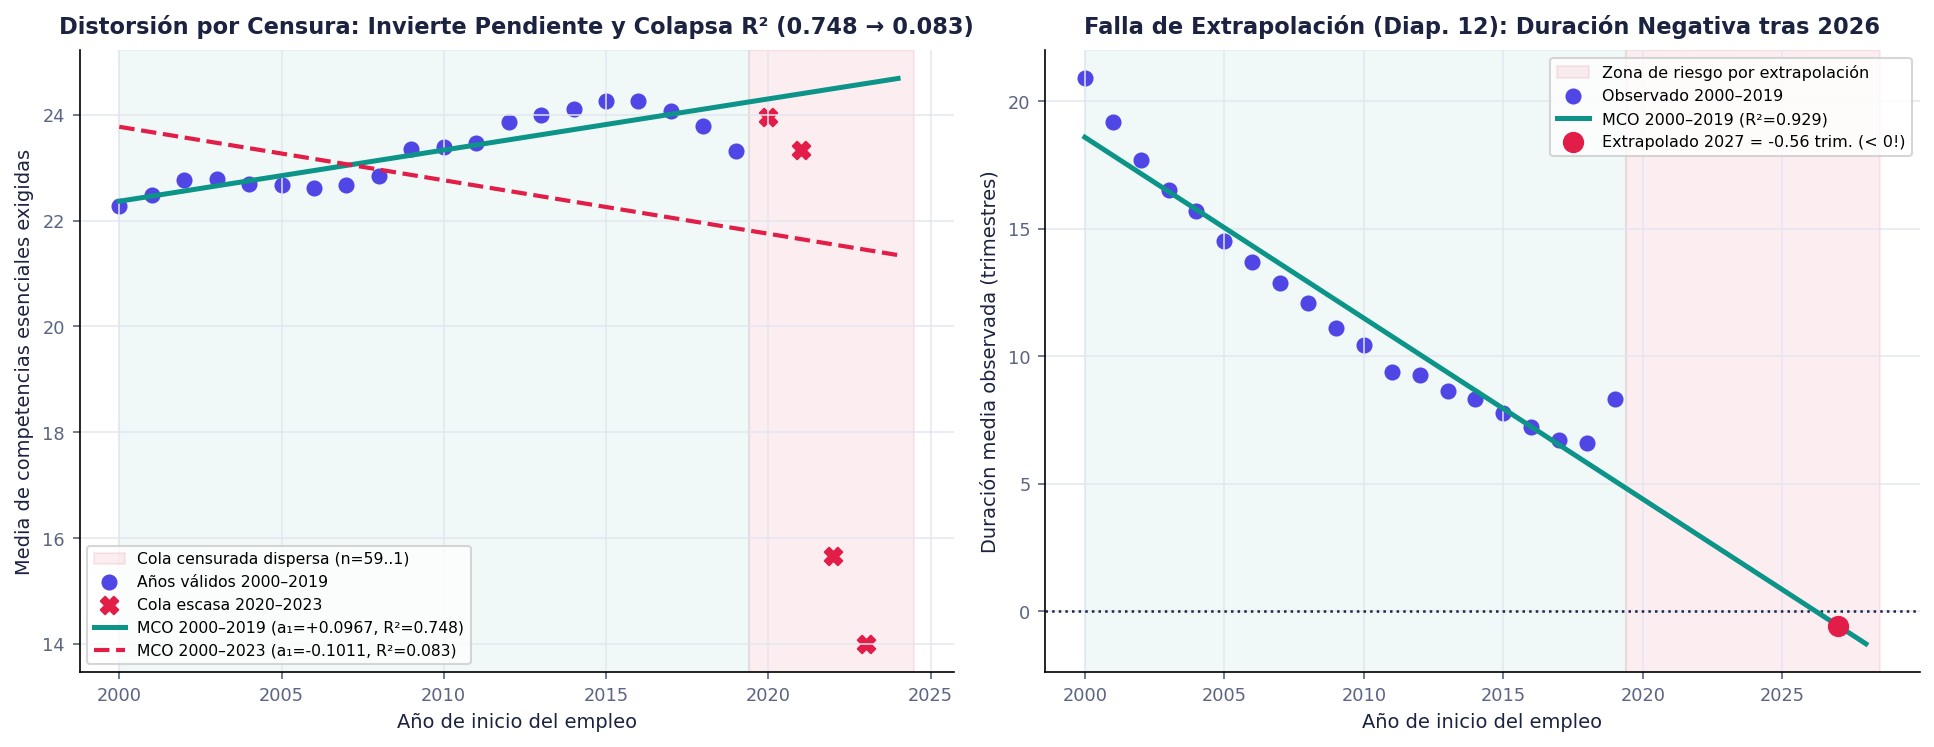

In [8]:
display(Image(filename=str(fdir / "nm05_rl04_annual_drift_and_censoring_extrapolation.png")))

## 5. `IDEA-RL-05` — Sensibilidad a Outliers en 4 Variantes y Prueba de Invarianza de Escala Afín en `04_transformed`

**Propósito:** Cuantificar cómo responde el criterio cuadrático de MCO a Versión A (colas crudas) vs. Versión B (winsorización IQR) vs. CSVs legados de `02_interim` (limpio vs. eliminación de filas), y verificar algebraica y numéricamente que `RobustScaler` en `data/04_transformed/` preserva $R^2$ exactamente mientras escala $(a_0, a_1, S_{y/x})$ con error `< 1e-10`.

In [9]:
print("Comparativa de las 4 estrategias frente a outliers:")
display(pd.read_csv(tdir / "rl05_four_way_outlier_comparison.csv")[["variant", "x_var", "y_var", "n", "a0", "a1", "r2", "s_yx", "polyfit_max_abs_diff"]])

print("\nVerificación de invarianza de escala afín en data/04_transformed (solo columnas densas):")
inv_df = pd.read_csv(tdir / "rl05_affine_scale_invariance.csv")
display(inv_df[["version", "split", "x_var", "y_var", "r2_raw", "r2_scaled_obs", "a1_scaled_obs", "a1_scaled_theory", "max_invariance_err", "passes_tol"]])
assert bool(inv_df["passes_tol"].all()), "¡Falló la tolerancia de invarianza afín!"

Comparativa de las 4 estrategias frente a outliers:


,variant,x_var,y_var,n,a0,a1,r2,s_yx,polyfit_max_abs_diff
0,Version A · With Outliers (03_processed),n_skills_competence,n_skills_essential,1738738,1.538833,1.127923,0.907198,4.087198,2.100542e-12
1,Version B · IQR Winsorized (03_processed),n_skills_competence,n_skills_essential,1738738,2.211221,1.086832,0.898269,3.191526,3.961276e-13
2,Legacy Clean · test+val (02_interim/empleos_li...,n_skills_competence,n_skills_essential,348263,1.445558,1.133561,0.904623,4.114744,2.684519e-13
3,Legacy Row-Dropped · test+val (02_interim/empl...,n_skills_competence,n_skills_essential,314904,1.384321,1.135124,0.906173,4.110462,5.155876e-13
4,Version A · With Outliers (03_processed),n_skills_knowledge,n_skills_essential,1738738,15.823072,1.882651,0.367959,10.666437,1.362288e-11
5,Version B · IQR Winsorized (03_processed),n_skills_knowledge,n_skills_essential,1738738,15.993238,1.672816,0.279529,8.493356,3.668355e-11
6,Legacy Clean · test+val (02_interim/empleos_li...,n_skills_knowledge,n_skills_essential,348263,15.726542,1.880552,0.379302,10.496931,3.028688e-12
7,Legacy Row-Dropped · test+val (02_interim/empl...,n_skills_knowledge,n_skills_essential,314904,15.737860,1.900611,0.382834,10.542129,1.523448e-12



Verificación de invarianza de escala afín en data/04_transformed (solo columnas densas):


,version,split,x_var,y_var,r2_raw,r2_scaled_obs,a1_scaled_obs,a1_scaled_theory,max_invariance_err,passes_tol
0,con_outliers,train,n_skills_competence,n_skills_essential,0.907188,0.907188,0.954776,0.954776,4.818368e-14,True
1,con_outliers,train,n_skills_knowledge,n_skills_essential,0.368903,0.368903,0.724744,0.724744,1.576517e-14,True
2,con_outliers,test,n_skills_competence,n_skills_essential,0.907241,0.907241,0.952868,0.952868,6.550316e-15,True
3,con_outliers,test,n_skills_knowledge,n_skills_essential,0.364146,0.364146,0.721463,0.721463,1.076916e-14,True
4,sin_outliers,train,n_skills_competence,n_skills_essential,0.898355,0.898355,0.919789,0.919789,9.658940e-15,True
5,sin_outliers,train,n_skills_knowledge,n_skills_essential,0.279903,0.279903,0.643817,0.643817,7.216450e-14,True
6,sin_outliers,test,n_skills_competence,n_skills_essential,0.897923,0.897923,0.918979,0.918979,5.329071e-15,True
7,sin_outliers,test,n_skills_knowledge,n_skills_essential,0.278033,0.278033,0.641680,0.641680,3.996803e-15,True


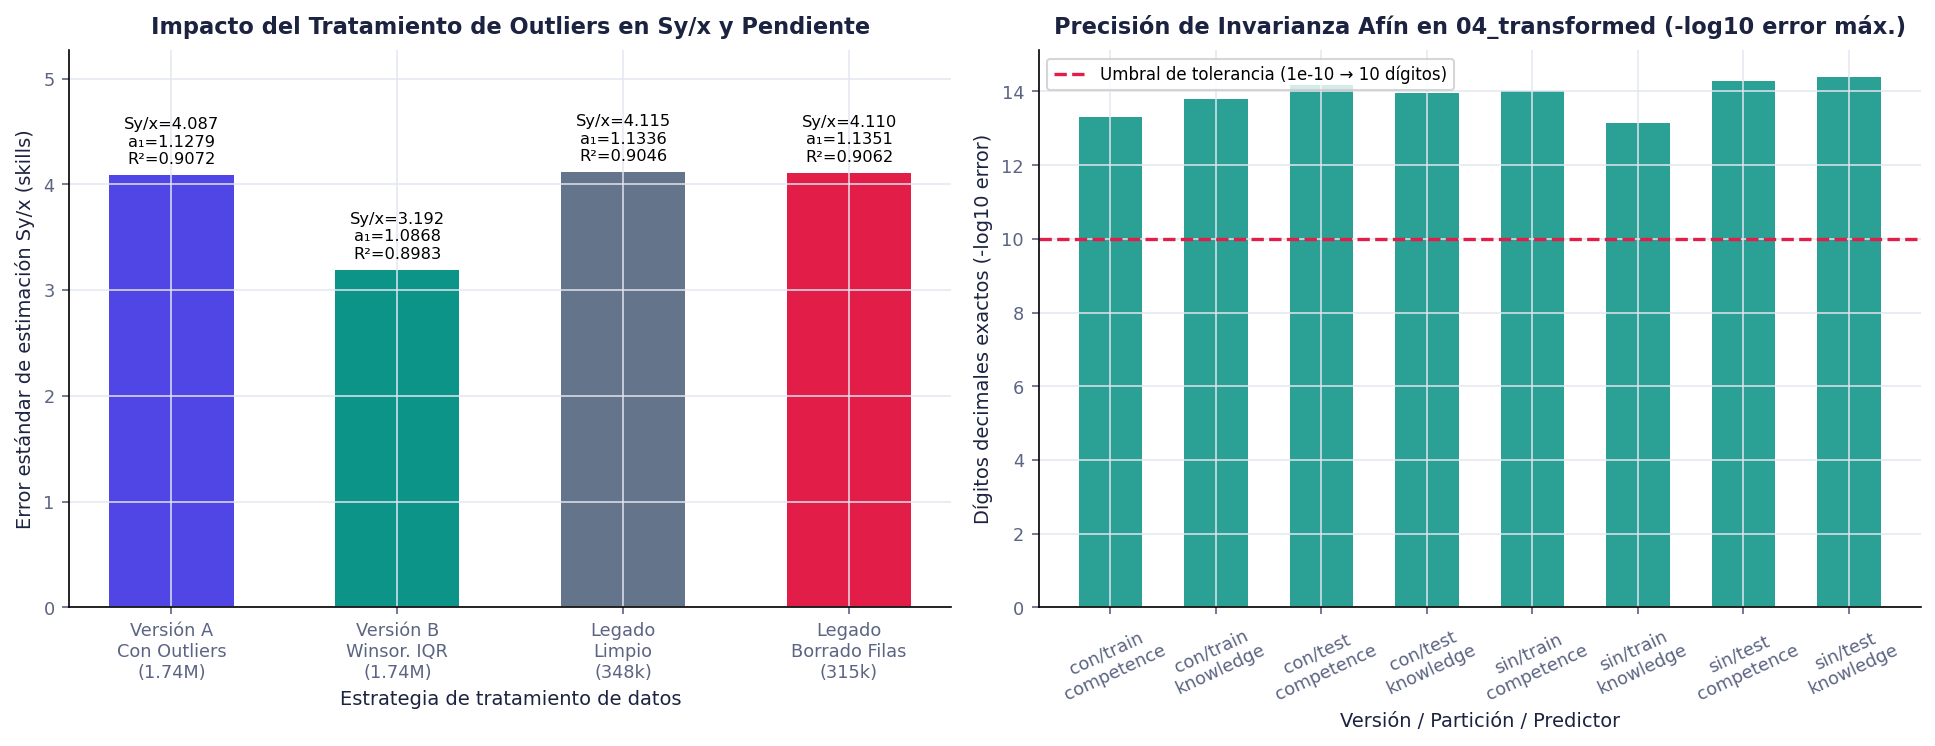

In [10]:
display(Image(filename=str(fdir / "nm06_rl05_outlier_strategies_and_scale_invariance.png")))